# Project 3: Earnings surprises and stock reactions, two industries compared
**Client:** Goldman Sachs (GS), SIC 62 | **Comparison industry:** Instruments (Medical), SIC 38 | **Course:** BAN 4550 Analytics Programming

**What this notebook does**
1. Runs the Project 2 pipeline (pull, merge, rules, returns, CAR) for both industries with exactly the same steps and rules.
2. Compares the two industries: Figure 1 (average CAR by SUE group), a t-test (high vs low SUE group), and regressions of CAR on SUE with Figure 2.
3. Checks one reason for the difference with Figure 3.

Code comes from my Project 2 notebook, which came from the class notebooks (Assignment 8, in-class 10 and 11). New in Project 3: the function that repeats the pipeline for a second industry, the t-test, the regressions and the figures.

## Setup

In [1]:
# ===== Setup: libraries and settings (Project 2 notebook, plus the libraries for the figures and tests) =====
import os
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # hide a harmless pandas warning

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.iolib.summary2 import summary_col
from scipy import stats
import wrds

conn = wrds.Connection()    # log in to WRDS

# Settings. If you want to change something, change it here only.
SIC_MAIN   = "62"            # my industry: Security & Commodity Brokers (client: Goldman Sachs)
SIC_COMP   = "38"            # comparison industry: Instruments (Medical)
NAME_MAIN  = "Brokers (SIC 62)"
NAME_COMP  = "Medical instruments (SIC 38)"
ANN_START  = "2021-01-01"    # rule: the announcement date must be on or after this date
ANN_END    = "2024-12-31"    # rule: the announcement date must be on or before this date
PULL_START = "2019-01-01"    # earlier quarters are pulled too: SUE needs EPS from four quarters ago
PULL_END   = "2024-12-31"    # last quarter-end date we pull
RET_START  = "2020-12-01"    # first day of daily returns
RET_END    = "2025-01-31"    # last day of daily returns
MIN_PRC    = 5               # rule: drop a quarter if last quarter's price is below this
MAX_SUE    = 1               # rule: drop a quarter if |SUE| is above this
LABELS     = ["Low", "Middle", "High"]

# A light grid behind the bars and dots in all figures (matplotlib setting).
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["axes.axisbelow"] = True

# One color per industry. The same colors are used in every figure.
COLORS = {NAME_MAIN: "#1f3a5f", NAME_COMP: "#d9822b"}

# Figures are saved here (the folder is uploaded to GitHub; figures contain only group averages and fitted lines).
os.makedirs("figures", exist_ok=True)

Loading library list...
Done


## Step 1. Read the link file and the market data (the same for both industries)

In [2]:
# ===== Step 1. Read the link file (Project 2 notebook, Step 1; unchanged except that both industries stay in the table) =====

# Read every column as text, so that nothing is changed or guessed at this point.
link_all = pd.read_csv("ccm_link.csv", dtype=str)

# gvkey must have 6 characters (for example 001690). Excel can drop the leading zeros, so we put them back.
link_all["gvkey"] = link_all["gvkey"].str.zfill(6)

# permno is a number.
link_all["permno"] = pd.to_numeric(link_all["permno"]).astype(int)

# The two date columns are text. Turn them into real dates, so that we can compare them with other dates.
link_all["linkdt"]    = pd.to_datetime(link_all["linkdt"], format="mixed", errors="coerce")
link_all["linkenddt"] = pd.to_datetime(link_all["linkenddt"], format="mixed", errors="coerce")

# A link with no end date is still valid, so we give it a far-future end date.
link_all["linkenddt"] = link_all["linkenddt"].fillna(pd.Timestamp("2099-12-31"))

# Check that both industries are in the file.
for sic in [SIC_MAIN, SIC_COMP]:
    n_links = int((link_all["sic2"] == sic).sum())
    print("SIC", sic, "| link rows:", n_links)
    if n_links == 0:
        raise ValueError("SIC " + sic + " is not in ccm_link.csv")

SIC 62 | link rows: 110
SIC 38 | link rows: 206


In [3]:
# ===== Step 1b. Pull the daily market return and number the trading days (Project 2 notebook, Steps 7a and 7b) =====
# The market table is the same for both industries, so we pull it once.
mkt = conn.raw_sql(f"""select date, vwretd from crsp.dsi
                       where date between '{RET_START}' and '{RET_END}'""",
                   date_cols=["date"])
mkt["vwretd"] = pd.to_numeric(mkt["vwretd"], errors="coerce").astype("float64")

# Sort by date and number the trading days 1, 2, 3, ... (the index starts at 0, so we add 1).
mkt = mkt.sort_values("date").reset_index(drop=True)
mkt["tday"] = mkt.index + 1

print("market days:", len(mkt), "| duplicate dates:", mkt.duplicated(["date"]).sum(), "(it must be 0)")

market days: 1027 | duplicate dates: 0 (it must be 0)


## Step 2. The Project 2 pipeline as a function
All steps and rules are the same as in Project 2. The only change is that the steps are inside one function, `build_events(sic)`, so that I can run them once for each industry. Every step has a comment. The function returns the final table (one row = one company-quarter announcement) and the row counts after each step.

In [4]:
# ===== Step 2. build_events(sic): the Project 2 pipeline for one industry =====
def build_events(sic):
    counts = []                                          # (step, rows after the step)

    # --- Pull quarterly earnings for the industry (Project 2, Step 4) ---
    link = link_all[link_all["sic2"] == sic].reset_index(drop=True)
    gv = "'" + "','".join(link["gvkey"].unique()) + "'"
    fq = conn.raw_sql(f"""
        select gvkey, datadate, fyearq, fqtr, rdq, epspxq, prccq
        from comp.fundq
        where gvkey in ({gv})
          and datadate between '{PULL_START}' and '{PULL_END}'
          and indfmt = 'INDL' and datafmt = 'STD' and popsrc = 'D' and consol = 'C'
    """, date_cols=["datadate", "rdq"])
    for col in ["fyearq", "fqtr", "epspxq", "prccq"]:
        fq[col] = pd.to_numeric(fq[col], errors="coerce").astype("float64")
    counts.append(("Compustat quarters pulled", len(fq)))

    # --- Merge 1: add permno, keep the link that was valid on the quarter-end date (Project 2, Steps 5a and 5b) ---
    panel = fq.merge(link[["gvkey", "permno", "ticker", "linkdt", "linkenddt"]], on="gvkey", how="inner")
    valid = (panel["linkdt"] <= panel["datadate"]) & (panel["datadate"] <= panel["linkenddt"])
    panel = panel[valid]
    panel = panel.drop_duplicates(["gvkey", "datadate"])
    panel = panel.drop(columns=["linkdt", "linkenddt"]).reset_index(drop=True)
    counts.append(("Merge 1: link", len(panel)))

    # --- Merge 2: EPS four quarters ago and last quarter's price (Project 2, Steps 5c and 5d) ---
    panel["qnum"] = panel["fyearq"] * 4 + panel["fqtr"]
    panel = panel.sort_values(["gvkey", "datadate"]).reset_index(drop=True)

    # The key gvkey + qnum must identify one row. If a company has two rows with the same quarter number
    # (for example after a change of the fiscal year-end), the merge below would repeat rows. We count them here.
    n_same_qnum = panel.duplicated(["gvkey", "qnum"]).sum()
    print("SIC", sic, "| rows that repeat a gvkey + qnum:", n_same_qnum)

    # Copies for the lags. drop_duplicates keeps one row for each gvkey + qnum (the one with the later datadate).
    eps4 = panel[["gvkey", "qnum", "epspxq"]].copy()
    eps4["qnum"] = eps4["qnum"] + 4
    eps4 = eps4.drop_duplicates(["gvkey", "qnum"], keep="last")
    eps4 = eps4.rename(columns={"epspxq": "eps_4q_ago"})
    prc1 = panel[["gvkey", "qnum", "prccq"]].copy()
    prc1["qnum"] = prc1["qnum"] + 1
    prc1 = prc1.drop_duplicates(["gvkey", "qnum"], keep="last")
    prc1 = prc1.rename(columns={"prccq": "prc_1q_ago"})

    rows_before_m2 = len(panel)
    panel = panel.merge(eps4, on=["gvkey", "qnum"], how="left")
    panel = panel.merge(prc1, on=["gvkey", "qnum"], how="left")
    if len(panel) != rows_before_m2:
        raise ValueError("Merge 2 changed the number of rows: " + str(rows_before_m2) + " -> " + str(len(panel)))
    counts.append(("Merge 2: EPS 4 quarters ago, price 1 quarter ago", len(panel)))

    # --- SUE (Project 2, Step 5e) ---
    panel["sue"] = (panel["epspxq"] - panel["eps_4q_ago"]) / panel["prc_1q_ago"]

    # --- Rules 1 to 5, one at a time (Project 2, Step 6) ---
    events = panel[panel["rdq"].notna()]
    counts.append(("Rule 1: announcement date known", len(events)))
    events = events[(events["rdq"] >= ANN_START) & (events["rdq"] <= ANN_END)]
    counts.append(("Rule 2: announcement Jan 2021 - Dec 2024", len(events)))
    events = events[events["sue"].notna()]
    counts.append(("Rule 3: SUE can be computed", len(events)))
    events = events[events["prc_1q_ago"] >= MIN_PRC]
    counts.append(("Rule 4: last quarter's price >= $5", len(events)))
    events = events[events["sue"].abs() <= MAX_SUE].reset_index(drop=True)
    counts.append(("Rule 5: |SUE| <= 1", len(events)))

    # --- Pull daily stock returns for the stocks we kept (Project 2, Step 7a) ---
    permnos = ",".join(events["permno"].astype(str).unique())
    stock = conn.raw_sql(f"""select permno, date, ret from crsp.dsf
                             where permno in ({permnos}) and date between '{RET_START}' and '{RET_END}'""",
                         date_cols=["date"])
    stock["permno"] = stock["permno"].astype(int)
    stock["ret"]    = pd.to_numeric(stock["ret"], errors="coerce").astype("float64")

    # --- Merge 3: add the market return and the trading-day number; abnormal return (Project 2, Step 7c) ---
    stock = stock.merge(mkt[["date", "tday", "vwretd"]], on="date", how="left")
    stock["ar"] = stock["ret"] - stock["vwretd"]
    stock_days = stock[stock["tday"].notna()]

    # --- Merge 4: day 0 = first trading day on or after the announcement date (Project 2, Step 8a) ---
    events["event_id"] = events.index
    pairs = events[["event_id", "rdq"]].merge(mkt[["date", "tday"]], how="cross")
    pairs = pairs[pairs["date"] >= pairs["rdq"]]
    day0 = pairs.groupby("event_id")["tday"].min().reset_index()
    day0 = day0.rename(columns={"tday": "day0"})
    events = events.merge(day0, on="event_id", how="left")

    # --- The window (days -1, 0, +1) and Merge 5: look up the abnormal returns (Project 2, Steps 8b and 8c) ---
    offsets = pd.DataFrame({"offset": [-1, 0, 1]})
    window = events[["event_id", "permno", "day0"]].merge(offsets, how="cross")
    window["tday"] = window["day0"] + window["offset"]
    window = window.merge(stock_days[["permno", "tday", "ar"]], on=["permno", "tday"], how="left")

    # --- CAR = the sum of the 3 abnormal returns; days_found = how many of the 3 exist (Project 2, Step 8d) ---
    car = window.groupby("event_id")["ar"].agg(["sum", "count"]).reset_index()
    car = car.rename(columns={"sum": "car", "count": "days_found"})
    events = events.merge(car, on="event_id", how="left")
    print("SIC", sic, "| days_found counts:", events["days_found"].value_counts().sort_index().to_dict())

    # --- Rule 6: all 3 daily abnormal returns exist (Project 2, Step 8e) ---
    events = events[events["days_found"] == 3].reset_index(drop=True)
    counts.append(("Rule 6: all 3 abnormal returns found", len(events)))

    # --- Check: the key appears only once (Project 2, Check 2) ---
    print("SIC", sic, "| duplicate gvkey + datadate:", events.duplicated(["gvkey", "datadate"]).sum(), "(it must be 0)")

    counts = pd.DataFrame(counts, columns=["step", "rows after"])
    return events, counts

## Step 3. Run the pipeline for both industries

In [5]:
# ===== Step 3a. Run build_events for my industry (Brokers, SIC 62) =====
events_main, counts_main = build_events(SIC_MAIN)
counts_main

SIC 62 | rows that repeat a gvkey + qnum: 0
SIC 62 | days_found counts: {0: 17, 3: 933}
SIC 62 | duplicate gvkey + datadate: 0 (it must be 0)


,step,rows after
0,Compustat quarters pulled,2095
1,Merge 1: link,2052
2,"Merge 2: EPS 4 quarters ago, price 1 quarter ago",2052
3,Rule 1: announcement date known,1613
4,Rule 2: announcement Jan 2021 - Dec 2024,1068
5,Rule 3: SUE can be computed,1034
6,Rule 4: last quarter's price >= $5,951
7,Rule 5: |SUE| <= 1,950
8,Rule 6: all 3 abnormal returns found,933


In [6]:
# ===== Step 3b. Run build_events for the comparison industry (Medical instruments, SIC 38) =====
events_comp, counts_comp = build_events(SIC_COMP)
counts_comp

SIC 38 | rows that repeat a gvkey + qnum: 4
SIC 38 | days_found counts: {0: 7, 3: 1768}
SIC 38 | duplicate gvkey + datadate: 0 (it must be 0)


,step,rows after
0,Compustat quarters pulled,3865
1,Merge 1: link,3654
2,"Merge 2: EPS 4 quarters ago, price 1 quarter ago",3654
3,Rule 1: announcement date known,3628
4,Rule 2: announcement Jan 2021 - Dec 2024,2414
5,Rule 3: SUE can be computed,2335
6,Rule 4: last quarter's price >= $5,1777
7,Rule 5: |SUE| <= 1,1775
8,Rule 6: all 3 abnormal returns found,1768


In [7]:
# ===== Step 3c. Sample construction table: the rows after every step, side by side =====
sample_table = counts_main.merge(counts_comp, on="step", suffixes=(" " + SIC_MAIN, " " + SIC_COMP))
print("companies in the final table:", SIC_MAIN, "=", events_main["gvkey"].nunique(), "|", SIC_COMP, "=", events_comp["gvkey"].nunique())
sample_table

companies in the final table: 62 = 67 | 38 = 151


,step,rows after 62,rows after 38
0,Compustat quarters pulled,2095,3865
1,Merge 1: link,2052,3654
2,"Merge 2: EPS 4 quarters ago, price 1 quarter ago",2052,3654
3,Rule 1: announcement date known,1613,3628
4,Rule 2: announcement Jan 2021 - Dec 2024,1068,2414
5,Rule 3: SUE can be computed,1034,2335
6,Rule 4: last quarter's price >= $5,951,1777
7,Rule 5: |SUE| <= 1,950,1775
8,Rule 6: all 3 abnormal returns found,933,1768


## Step 4. Prepare the variables for the comparison
- **SUE in %** and **CAR in %**: the same numbers multiplied by 100, so that results are easier to read. A rescaling does not change t-statistics, p-values or R-squared.
- **Loss**: 1 if the quarter's EPS is below 0.
- **Group**: low, middle, high SUE, cut **within each industry** (rank first, so that ties cannot make the groups unequal).

In [8]:
# ===== Step 4. Add the new variables to each industry's table (hint from the handout, in-class 10) =====
def prepare(df, name):
    d = df.copy()
    d["industry"] = name
    d["sue_pct"]  = d["sue"] * 100                       # SUE in % of the price
    d["car_pct"]  = d["car"] * 100                       # CAR in %
    d["loss"]     = (d["epspxq"] < 0).astype(int)        # 1 if EPS is below 0
    d["group"]    = pd.qcut(d["sue"].rank(method="first"), 3, labels=LABELS)
    return d

main = prepare(events_main, NAME_MAIN)
comp = prepare(events_comp, NAME_COMP)
both = pd.concat([main, comp], ignore_index=True)
print("announcements:", NAME_MAIN, "=", len(main), "|", NAME_COMP, "=", len(comp))

announcements: Brokers (SIC 62) = 933 | Medical instruments (SIC 38) = 1768


## Figure 1. Average CAR by SUE group, both industries, with 95% confidence intervals

In [9]:
# ===== Figure 1a. Number of announcements, average CAR and 95% confidence interval for each industry and group =====
summary = both.groupby(["industry", "group"], observed=True)["car_pct"].agg(["count", "mean", "std"]).reset_index()

# Standard error = standard deviation / square root of the number of announcements.
summary["se"] = summary["std"] / np.sqrt(summary["count"])

# 95% confidence interval = mean +/- 1.96 x standard error (this is the error bar in Figure 1).
summary["ci95"] = 1.96 * summary["se"]
summary[["industry", "group", "count", "mean", "ci95"]].round(3)

,industry,group,count,mean,ci95
0,Brokers (SIC 62),Low,311,-0.268,0.719
1,Brokers (SIC 62),Middle,311,-0.144,0.730
2,Brokers (SIC 62),High,311,2.551,1.000
3,Medical instruments (SIC 38),Low,589,-2.006,0.818
4,Medical instruments (SIC 38),Middle,589,-0.281,0.695
5,Medical instruments (SIC 38),High,590,1.718,0.891


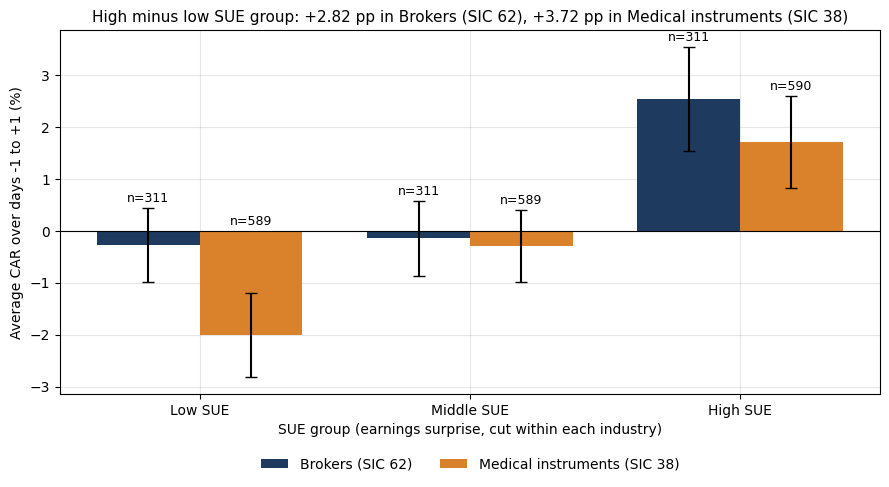

In [10]:
# ===== Figure 1b. The bar chart (error bars = 95% confidence interval) =====
# The difference High - Low in each industry is used in the title (it is also tested in the t-test below).
d_main = summary.query("industry == @NAME_MAIN and group == 'High'")["mean"].iloc[0] - summary.query("industry == @NAME_MAIN and group == 'Low'")["mean"].iloc[0]
d_comp = summary.query("industry == @NAME_COMP and group == 'High'")["mean"].iloc[0] - summary.query("industry == @NAME_COMP and group == 'Low'")["mean"].iloc[0]

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(3)                                          # three groups: Low, Middle, High
width = 0.38

for i, name in enumerate([NAME_MAIN, NAME_COMP]):
    sub = summary[summary["industry"] == name].set_index("group").loc[LABELS]
    xpos = x + (i - 0.5) * width                          # shift the two industries left and right of the group position
    ax.bar(xpos, sub["mean"], width, yerr=sub["ci95"], capsize=4, color=COLORS[name], label=name)
    # Write the number of announcements (n) above each bar's confidence interval.
    for xp, m, ci, n in zip(xpos, sub["mean"], sub["ci95"], sub["count"]):
        ax.annotate("n=" + str(int(n)), (xp, max(m + ci, 0)), textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels([label + " SUE" for label in LABELS])
ax.set_xlabel("SUE group (earnings surprise, cut within each industry)")
ax.set_ylabel("Average CAR over days -1 to +1 (%)")
# The title states the finding. Rewrite it to match your story after you have seen the numbers.
ax.set_title("High minus low SUE group: " + format(d_main, "+.2f") + " pp in " + NAME_MAIN + ", " + format(d_comp, "+.2f") + " pp in " + NAME_COMP, fontsize=11)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False)   # legend below the plot, so it covers no bars
plt.tight_layout()
fig.savefig("figures/figure1_car_by_sue_group.png", dpi=200, bbox_inches="tight")
plt.show()

## Is the difference real? t-test
For each industry: does the average CAR of the high SUE group differ from the low SUE group? I use Welch's t-test (`equal_var=False`), which does not assume that both groups have the same spread.

In [11]:
# ===== t-test: high SUE group vs low SUE group, for each industry =====

# Write a p-value with 4 decimals. A p-value below 0.0001 would show as 0.0000, so we write "<0.0001" instead.
def format_p(p):
    if p < 0.0001:
        return "<0.0001"
    return format(p, ".4f")

ttest_rows = []
for name, df in [(NAME_MAIN, main), (NAME_COMP, comp)]:
    high = df.loc[df["group"] == "High", "car_pct"]      # CAR of the high SUE group
    low  = df.loc[df["group"] == "Low", "car_pct"]       # CAR of the low SUE group
    t_stat, p_value = stats.ttest_ind(high, low, equal_var=False)
    ttest_rows.append({"industry": name,
                       "average CAR high (%)": high.mean(),
                       "average CAR low (%)": low.mean(),
                       "difference high - low (pp)": high.mean() - low.mean(),
                       "t-statistic": t_stat,
                       "p-value": format_p(p_value)})

ttest_table = pd.DataFrame(ttest_rows)
ttest_table.round(4)

,industry,average CAR high (%),average CAR low (%),difference high - low (pp),t-statistic,p-value
0,Brokers (SIC 62),2.5514,-0.2682,2.8196,4.4879,<0.0001
1,Medical instruments (SIC 38),1.7183,-2.0058,3.7241,6.0338,<0.0001


## How strong is the link? Regression CAR = a + b x SUE
`car_pct` is CAR in %, `sue_pct` is SUE in % of the price. **b** is the change in CAR (in percentage points) when SUE is 1 percentage point higher.

In [12]:
# ===== Regression (1): CAR = a + b x SUE, for each industry =====
models = {}
reg_rows = []
for name, df in [(NAME_MAIN, main), (NAME_COMP, comp)]:
    model = smf.ols("car_pct ~ sue_pct", data=df).fit()
    models[name] = model
    reg_rows.append({"industry": name,
                     "a (intercept)": model.params["Intercept"],
                     "b (slope)": model.params["sue_pct"],
                     "p-value of b": format_p(model.pvalues["sue_pct"]),
                     "R-squared": model.rsquared,
                     "announcements": int(model.nobs)})

reg_table = pd.DataFrame(reg_rows)
reg_table.round(4)

,industry,a (intercept),b (slope),p-value of b,R-squared,announcements
0,Brokers (SIC 62),0.6724,0.1250,<0.0001,0.0226,933
1,Medical instruments (SIC 38),-0.1897,0.0901,0.0897,0.0016,1768


### Recommended: the models from class side by side
(1) simple, (2) with year fixed effects `C(fyearq)`, (3) with `sue * loss` (loss = 1 if EPS < 0). Does b stay about the same?

In [13]:
# ===== Recommended models (2) and (3) with summary_col, one table for each industry =====
for name, df in [(NAME_MAIN, main), (NAME_COMP, comp)]:
    m1 = smf.ols("car_pct ~ sue_pct", data=df).fit()
    m2 = smf.ols("car_pct ~ sue_pct + C(fyearq)", data=df).fit()
    m3 = smf.ols("car_pct ~ sue_pct * loss", data=df).fit()

    table = summary_col([m1, m2, m3],
                        stars=True,
                        model_names=["(1) simple", "(2) year FE", "(3) sue*loss"],
                        info_dict={"N": lambda m: str(int(m.nobs))},
                        regressor_order=["Intercept", "sue_pct", "loss", "sue_pct:loss"],
                        drop_omitted=True,
                        float_format="%.4f")
    print(name)
    print(table)
    print()

Brokers (SIC 62)

               (1) simple (2) year FE (3) sue*loss
--------------------------------------------------
Intercept      0.6724***  4.0413***   0.7804***   
               (0.2444)   (1.0038)    (0.2537)    
sue_pct        0.1250***  0.1185***   0.2378***   
               (0.0269)   (0.0271)    (0.0347)    
loss                                  -3.8925***  
                                      (0.8624)    
sue_pct:loss                          -0.3479***  
                                      (0.0558)    
R-squared      0.0226     0.0496      0.0709      
R-squared Adj. 0.0216     0.0445      0.0679      
N              933        933         933         
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01

Medical instruments (SIC 38)

               (1) simple (2) year FE (3) sue*loss
--------------------------------------------------
Intercept      -0.1897    0.1829      0.2679      
               (0.2398)   (1.0042)    (0.2850)    
sue_pct        0.0901*   

## Figure 2. SUE and CAR, one color per industry, with each industry's regression line

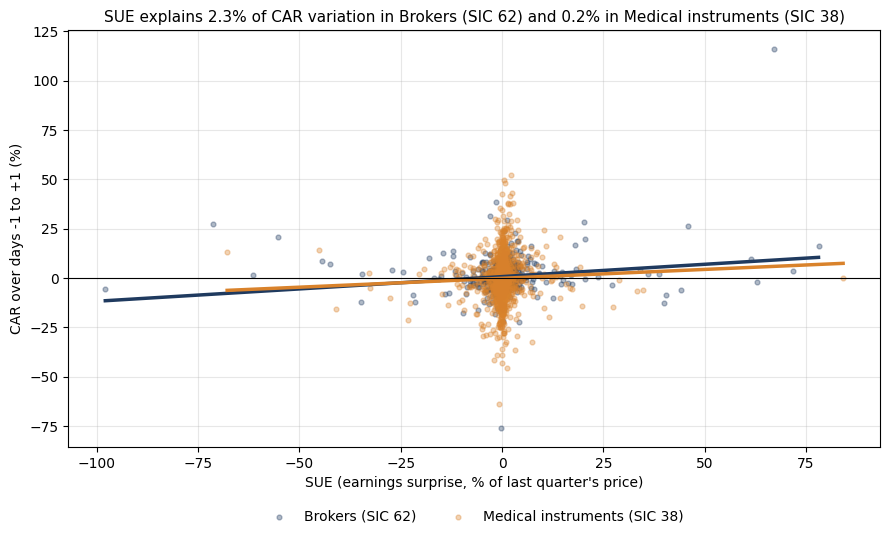

In [14]:
# ===== Figure 2. Scatter plot with regression lines =====
fig, ax = plt.subplots(figsize=(9, 5.5))

for name, df in [(NAME_MAIN, main), (NAME_COMP, comp)]:
    # One color per industry.
    ax.scatter(df["sue_pct"], df["car_pct"], s=12, alpha=0.35, color=COLORS[name], label=name)

    # The regression line: y = a + b x, drawn from the smallest to the largest SUE of this industry.
    a = models[name].params["Intercept"]
    b = models[name].params["sue_pct"]
    x_line = np.linspace(df["sue_pct"].min(), df["sue_pct"].max(), 50)
    ax.plot(x_line, a + b * x_line, color=COLORS[name], linewidth=2.5)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("SUE (earnings surprise, % of last quarter's price)")
ax.set_ylabel("CAR over days -1 to +1 (%)")
# The title states the finding (R-squared = share of the variation in CAR that SUE explains). Edit it to match your story.
ax.set_title("SUE explains " + format(models[NAME_MAIN].rsquared, ".1%") + " of CAR variation in " + NAME_MAIN + " and " + format(models[NAME_COMP].rsquared, ".1%") + " in " + NAME_COMP, fontsize=11)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)   # legend below the plot
plt.tight_layout()
fig.savefig("figures/figure2_sue_vs_car.png", dpi=200, bbox_inches="tight")
plt.show()

## Why do the industries differ? Reason to check: the share of loss-making quarters
**Reason (my proposal, change it if you prefer another):** in an industry with many loss-making quarters, EPS changes are noisy, so SUE may say less about how good the news is. 
**Test (Figure 3):** (A) the share of loss-making announcements in each industry. (B) the slope b in each industry for all announcements and for profitable quarters only. If the reason is right, the two industries' slopes should become more similar once losses are removed.

In [15]:
# ===== Figure 3a. The numbers: share of loss quarters, and the slope b with and without loss quarters =====
loss_share = both.groupby("industry")["loss"].mean() * 100          # % of announcements with EPS below 0

slope_rows = []
for name, df in [(NAME_MAIN, main), (NAME_COMP, comp)]:
    for label, data in [("All quarters", df), ("Profitable quarters only", df[df["loss"] == 0])]:
        model = smf.ols("car_pct ~ sue_pct", data=data).fit()
        low, high = model.conf_int().loc["sue_pct"]                # 95% confidence interval of b
        slope_rows.append({"industry": name, "sample": label, "b": model.params["sue_pct"],
                           "ci_low": low, "ci_high": high, "n": int(model.nobs)})

slopes = pd.DataFrame(slope_rows)
print(loss_share.round(1))
slopes.round(3)

industry
Brokers (SIC 62)                 9.6
Medical instruments (SIC 38)    27.8
Name: loss, dtype: float64


,industry,sample,b,ci_low,ci_high,n
0,Brokers (SIC 62),All quarters,0.125,0.072,0.178,933
1,Brokers (SIC 62),Profitable quarters only,0.238,0.174,0.301,843
2,Medical instruments (SIC 38),All quarters,0.090,-0.014,0.194,1768
3,Medical instruments (SIC 38),Profitable quarters only,0.119,-0.022,0.260,1276


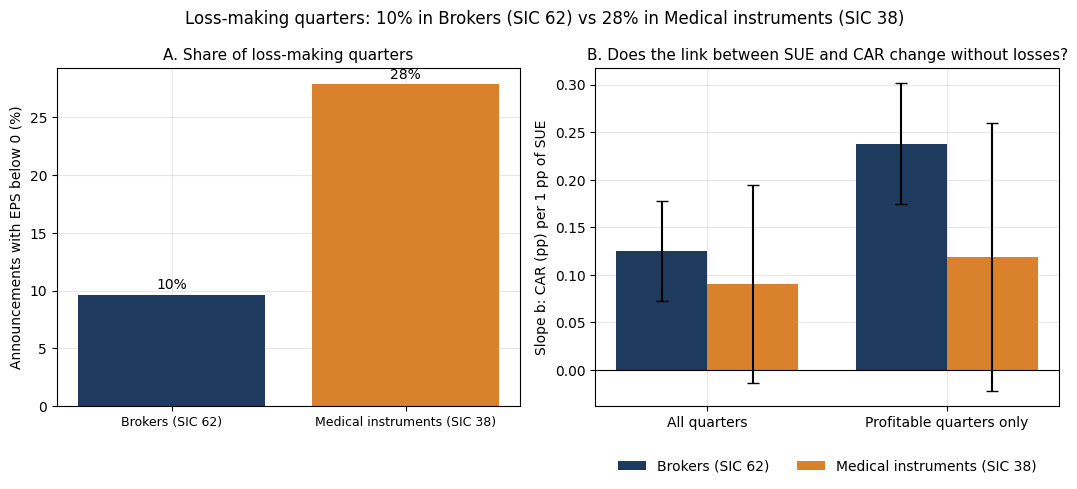

In [16]:
# ===== Figure 3b. Two panels: (A) share of loss quarters, (B) slope b with and without loss quarters =====
fig, (axA, axB) = plt.subplots(1, 2, figsize=(11, 5))

# Panel A: share of loss-making announcements.
for i, name in enumerate([NAME_MAIN, NAME_COMP]):
    axA.bar(i, loss_share[name], color=COLORS[name])
    axA.annotate(format(loss_share[name], ".0f") + "%", (i, loss_share[name]), textcoords="offset points", xytext=(0, 4), ha="center")
axA.set_xticks([0, 1])
axA.set_xticklabels([NAME_MAIN, NAME_COMP], fontsize=9)
axA.set_ylabel("Announcements with EPS below 0 (%)")
axA.set_title("A. Share of loss-making quarters", fontsize=11)

# Panel B: slope b (with 95% confidence interval) for all quarters and for profitable quarters only.
x = np.arange(2)
width = 0.38
for i, name in enumerate([NAME_MAIN, NAME_COMP]):
    sub = slopes[slopes["industry"] == name].set_index("sample").loc[["All quarters", "Profitable quarters only"]]
    xpos = x + (i - 0.5) * width
    err = [sub["b"] - sub["ci_low"], sub["ci_high"] - sub["b"]]       # distance down and up from b to the interval ends
    axB.bar(xpos, sub["b"], width, yerr=err, capsize=4, color=COLORS[name], label=name)
axB.axhline(0, color="black", linewidth=0.8)
axB.set_xticks(x)
axB.set_xticklabels(["All quarters", "Profitable quarters only"])
axB.set_ylabel("Slope b: CAR (pp) per 1 pp of SUE")
axB.set_title("B. Does the link between SUE and CAR change without losses?", fontsize=11)
axB.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)   # legend below the plot

# The title states the finding. Rewrite it after you have seen the numbers.
fig.suptitle("Loss-making quarters: " + format(loss_share[NAME_MAIN], ".0f") + "% in " + NAME_MAIN + " vs " + format(loss_share[NAME_COMP], ".0f") + "% in " + NAME_COMP, fontsize=12)
plt.tight_layout()
fig.savefig("figures/figure3_loss_share_and_slope.png", dpi=200, bbox_inches="tight")
plt.show()

## Group averages (the only results that go to GitHub, together with the figures)

In [17]:
# ===== Group averages for the README: no company-level data =====
group_table = summary[["industry", "group", "count", "mean", "ci95"]].rename(columns={"count": "announcements", "mean": "average CAR (%)", "ci95": "95% CI (+/- pp)"})
group_table.round(3)

,industry,group,announcements,average CAR (%),95% CI (+/- pp)
0,Brokers (SIC 62),Low,311,-0.268,0.719
1,Brokers (SIC 62),Middle,311,-0.144,0.730
2,Brokers (SIC 62),High,311,2.551,1.000
3,Medical instruments (SIC 38),Low,589,-2.006,0.818
4,Medical instruments (SIC 38),Middle,589,-0.281,0.695
5,Medical instruments (SIC 38),High,590,1.718,0.891


In [18]:
conn.close()